# 4. Predicting heart disease

The earlier notebooks asked *which factors are associated* with heart disease. This one asks the second half of the project question: **how well can heart disease be predicted from these variables?**

Plan:

1. Hold out a test set; do all model selection by cross-validation on the training set.
2. Compare a majority-class baseline, logistic regression and gradient boosting (LightGBM).
3. Deal with the 11-to-1 class imbalance without distorting the predicted probabilities.
4. Evaluate once on the test set with metrics that suit a rare outcome.
5. Repeat with lifestyle and demographic variables only (the leakage question from notebook 3).
6. Explain the final model with SHAP and save it for the app.

Every random step uses seed 42.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")  # shap's optional progress-bar widget
import shap  # noqa: E402
from sklearn.metrics import average_precision_score  # noqa: E402

from cvd import SEED, data, models, plots
from cvd.data import TARGET
from cvd.features import FEATURE_SETS, FEATURES_ALL, FEATURES_LIFESTYLE

plots.set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 200)

df = data.load_clean()
train, test = models.train_test(df, test_size=0.2, seed=SEED)
y_train, y_test = train[TARGET], test[TARGET]
base_rate = y_train.mean()

print(f"Train: {len(train):,} rows, prevalence {y_train.mean():.4f}")
print(f"Test:  {len(test):,} rows, prevalence {y_test.mean():.4f}")

Train: 247,019 rows, prevalence 0.0809
Test:  61,755 rows, prevalence 0.0809


The split is stratified, so both parts have the same 8.09% prevalence. The test set is not touched again until section 4.4.

## 4.1 Metrics

Accuracy is not reported as a headline number: predicting "no heart disease" for everyone is 91.9% accurate and useless.

| Metric | What it measures | Value for a model with no skill |
|---|---|---|
| **PR-AUC** (average precision), primary | How well the model ranks positives first, focused on the rare class | The prevalence, 0.081 |
| ROC-AUC | Probability that a random positive is ranked above a random negative | 0.5 |
| Brier score | Mean squared error of the predicted probabilities (lower is better); rewards calibration | 0.0743, from predicting the prevalence for everyone |
| Precision and recall at a threshold | What happens when the probabilities are turned into a yes/no flag | depends on the threshold |

PR-AUC is the primary metric because with a rare outcome ROC-AUC looks flattering: it gives credit for ranking the very large group of obvious negatives correctly.

## 4.2 Candidates and cross-validation

Stratified 5-fold cross-validation on the training set, using all 16 predictors. Candidates:

- **Majority-class baseline:** predicts the training prevalence for everyone.
- **Logistic regression:** one-hot encoded categories, standardised numeric variables.
- **LightGBM:** gradient-boosted trees at three sizes (7, 15 and 31 leaves per tree). LightGBM was chosen over XGBoost because it trains in seconds on 250,000 rows on a laptop and has exact, fast SHAP values; the two libraries perform alike on tabular data of this kind.
- **Class-weighted versions** of both, where a positive counts about 11 times as much as a negative during training.

In [2]:
pos_weight = (1 - base_rate) / base_rate
candidates = {
    "Majority-class baseline": models.make_dummy_pipeline(),
    "Logistic regression": models.make_logreg_pipeline(FEATURES_ALL),
    "Logistic regression, class-weighted": models.make_logreg_pipeline(FEATURES_ALL, class_weight="balanced"),
    "LightGBM, 7 leaves": models.make_lgbm_pipeline(FEATURES_ALL, num_leaves=7),
    "LightGBM, 15 leaves": models.make_lgbm_pipeline(FEATURES_ALL, num_leaves=15),
    "LightGBM, 31 leaves": models.make_lgbm_pipeline(FEATURES_ALL, num_leaves=31),
    "LightGBM, 7 leaves, class-weighted": models.make_lgbm_pipeline(FEATURES_ALL, num_leaves=7, scale_pos_weight=pos_weight),
}

oof, fold_metrics = {}, {}
for name, pipeline in candidates.items():
    oof[name], fold_metrics[name] = models.cross_val_oof(pipeline, train[FEATURES_ALL], y_train)

cv_table = pd.DataFrame(
    {
        name: {
            "PR-AUC mean": folds["pr_auc"].mean(),
            "PR-AUC sd": folds["pr_auc"].std(),
            "ROC-AUC mean": folds["roc_auc"].mean(),
            "Brier mean": folds["brier"].mean(),
        }
        for name, folds in fold_metrics.items()
    }
).T
cv_table

,PR-AUC mean,PR-AUC sd,ROC-AUC mean,Brier mean
Majority-class baseline,0.0809,0.0000,0.5000,0.0743
Logistic regression,0.3065,0.0073,0.8337,0.0640
"Logistic regression, class-weighted",0.3059,0.0075,0.8339,0.1725
"LightGBM, 7 leaves",0.3077,0.0070,0.8363,0.0638
"LightGBM, 15 leaves",0.3071,0.0067,0.8362,0.0638
"LightGBM, 31 leaves",0.3056,0.0070,0.8358,0.0638
"LightGBM, 7 leaves, class-weighted",0.3082,0.0073,0.8364,0.1739


In [3]:
paired = fold_metrics["LightGBM, 7 leaves"]["pr_auc"] - fold_metrics["Logistic regression"]["pr_auc"]
print("PR-AUC per fold, LightGBM (7 leaves) minus logistic regression:")
print(paired.round(4).to_string())
print(f"Mean difference {paired.mean():.4f}; LightGBM ahead in {int((paired > 0).sum())} of {len(paired)} folds")

PR-AUC per fold, LightGBM (7 leaves) minus logistic regression:
fold
0    0.0022
1    0.0039
2    0.0011
3    0.0007
4   -0.0018
Mean difference 0.0012; LightGBM ahead in 4 of 5 folds


**What cross-validation shows.**

- **Both real models are far above the baseline**, with PR-AUC around 0.31 against 0.08.
- **LightGBM barely beats logistic regression.** The gain in PR-AUC is about 0.001, far smaller than the fold-to-fold standard deviation of 0.007, and LightGBM is ahead in 4 of the 5 folds, not all. The signal in this data is close to additive: once age, sex and health status are in, there is little interaction structure for trees to find.
- **Smaller trees are at least as good as larger ones.** Among the unweighted LightGBM models the 7-leaf one has the highest PR-AUC, so it is used from here on.
- **Class weighting does not improve ranking** (PR-AUC and ROC-AUC move by less than 0.001 for both model types) **and it ruins the probabilities**: the Brier score nearly triples, from 0.064 to about 0.17, because a weighted model systematically overstates risk.

### Handling the imbalance

The decision that follows from the last point: **train without class weights and handle the imbalance at the decision threshold instead.** That keeps the predicted probabilities meaningful ("about 20% of people like this report heart disease"), which the app in this project relies on, and loses nothing in ranking quality. No resampling is used anywhere, so the test set keeps the true prevalence.

## 4.3 Choosing a decision threshold

A probability becomes a decision only once a threshold is set. The default of 0.5 makes no sense here: almost nobody has a predicted probability above 0.5 when the base rate is 8%.

The threshold is chosen on the **out-of-fold training predictions**, never on the test set, by maximising **F2**. F2 is the F-score that weights recall twice as much as precision. The reasoning: if such a model were used at all, it would be to suggest who might benefit from a check-up, where missing a person with heart disease costs more than flagging someone unnecessarily. This is a stated assumption about costs, not a fact, so the table below also shows what other thresholds would give.

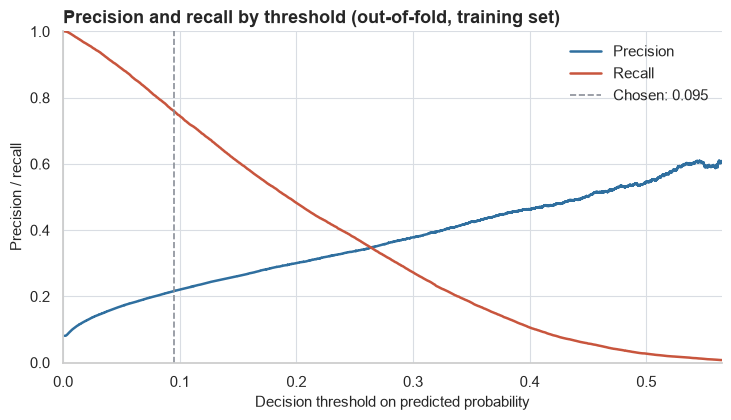

F2-optimal threshold: 0.0955
threshold       0.0955
precision       0.2165
recall          0.7586
flagged_share   0.2834 

Alternative operating points (out-of-fold):


,threshold,precision,recall,flagged_share
target_recall,,,,
0.5000,0.1926,0.2951,0.5000,0.1370
0.7000,0.1164,0.2346,0.7000,0.2413
0.8000,0.0810,0.2023,0.8000,0.3199
0.9000,0.0457,0.1653,0.9000,0.4405


In [4]:
FINAL = "LightGBM, 7 leaves"
threshold_all = models.best_fbeta_threshold(y_train, oof[FINAL], beta=2.0)

fig, ax = plt.subplots(figsize=(8.5, 4.3))
plots.threshold_curve(y_train, oof[FINAL], ax, "Precision and recall by threshold (out-of-fold, training set)", chosen=threshold_all)
plt.show()

print(f"F2-optimal threshold: {threshold_all:.4f}")
print(pd.Series(models.threshold_metrics(y_train, oof[FINAL], threshold_all)).round(4).to_string(), "\n")
print("Alternative operating points (out-of-fold):")
models.threshold_table(y_train, oof[FINAL], [0.5, 0.7, 0.8, 0.9])

**Takeaway.** There is no threshold with both high precision and high recall; the curves cross low. The F2-optimal threshold (0.096) flags 28% of respondents, finds 76% of the people with heart disease, and is right about one flag in five (precision 22%). Pushing recall to 90% means flagging 44% of everyone. This is the practical ceiling of what these survey variables allow.

## 4.4 Final models and test-set evaluation

Each model is refitted on the full training set and evaluated once on the held-out test set. The same procedure is run for both feature sets:

- **All predictors** (16 variables).
- **Lifestyle and demographics only** (9 variables): no self-rated health, checkups or diagnoses. This is the model that does not lean on information a person typically has only *after* becoming a patient.

For the lifestyle set, the LightGBM size and the threshold are again chosen by cross-validation on the training data.

In [5]:
def pr_auc(y_true, y_prob):
    return average_precision_score(y_true, y_prob)


fitted, test_prob, thresholds, rows = {}, {}, {}, []
for set_name, feature_list in FEATURE_SETS.items():
    specs = {
        "Majority-class baseline": models.make_dummy_pipeline(),
        "Logistic regression": models.make_logreg_pipeline(feature_list),
        "LightGBM": models.make_lgbm_pipeline(feature_list, num_leaves=7),
    }
    for model_name, pipeline in specs.items():
        key = (set_name, model_name)
        oof_prob, folds = models.cross_val_oof(pipeline, train[feature_list], y_train)
        fitted[key] = pipeline.fit(train[feature_list], y_train)
        test_prob[key] = fitted[key].predict_proba(test[feature_list])[:, 1]
        row = {"feature_set": set_name, "model": model_name, "cv_pr_auc": folds["pr_auc"].mean()}
        row.update(models.probability_metrics(y_test, test_prob[key]))
        if model_name != "Majority-class baseline":
            thresholds[key] = models.best_fbeta_threshold(y_train, oof_prob, beta=2.0)
            row["pr_auc_low"], row["pr_auc_high"] = models.bootstrap_metric_ci(y_test, test_prob[key], pr_auc, n_boot=500)
            row.update(models.threshold_metrics(y_test, test_prob[key], thresholds[key]))
        rows.append(row)

results = pd.DataFrame(rows).set_index(["feature_set", "model"])
results[["cv_pr_auc", "pr_auc", "pr_auc_low", "pr_auc_high", "roc_auc", "brier"]]

cv_pr_auc  pr_auc  pr_auc_low  pr_auc_high  roc_auc  brier
feature_set model                                                                              
all         Majority-class baseline     0.0809  0.0809         NaN          NaN   0.5000 0.0743
            Logistic regression         0.3065  0.3150      0.3032       0.3284   0.8383 0.0635
            LightGBM                    0.3077  0.3169      0.3052       0.3298   0.8410 0.0633
lifestyle   Majority-class baseline     0.0809  0.0809         NaN          NaN   0.5000 0.0743
            Logistic regression         0.2289  0.2371      0.2268       0.2471   0.7920 0.0674
            LightGBM                    0.2321  0.2410      0.2303       0.2516   0.7985 0.0671

In [6]:
results.loc[results["threshold"].notna(), ["threshold", "precision", "recall", "flagged_share"]]

threshold  precision  recall  flagged_share
feature_set model                                                           
all         Logistic regression     0.0909     0.2180  0.7733         0.2869
            LightGBM                0.0955     0.2211  0.7723         0.2825
lifestyle   Logistic regression     0.0912     0.1778  0.7431         0.3380
            LightGBM                0.0853     0.1762  0.7799         0.3579

`cv_pr_auc` is the cross-validated estimate from the training set; `pr_auc` is the test-set value with a 95% bootstrap interval (500 resamples of the test rows). The second table uses each model's F2-optimal threshold, fixed before the test set was scored.

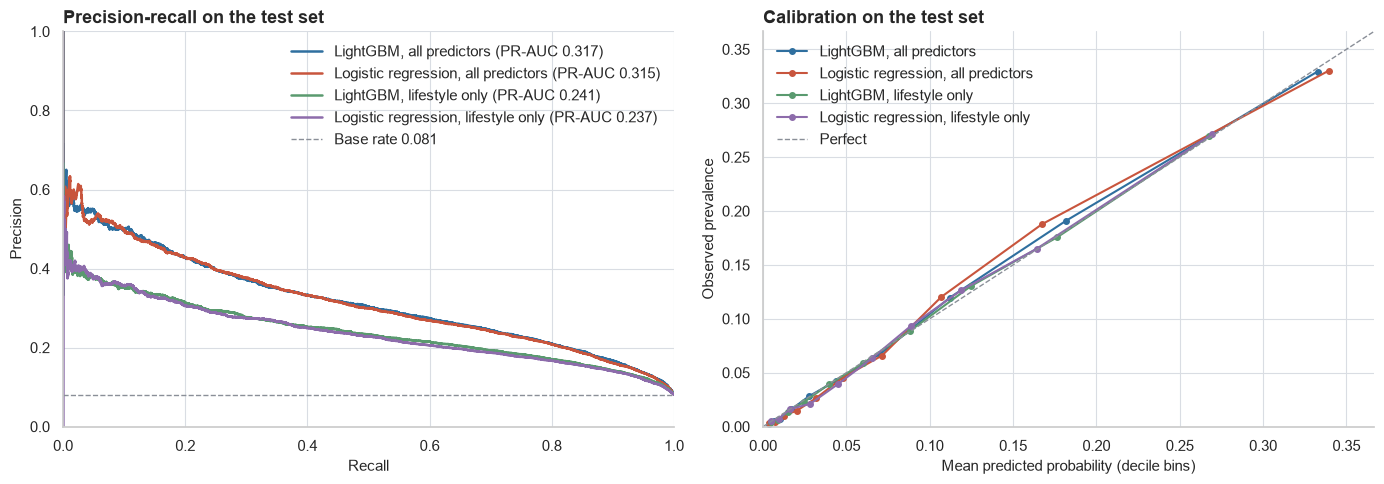

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
curves = {
    "LightGBM, all predictors": test_prob[("all", "LightGBM")],
    "Logistic regression, all predictors": test_prob[("all", "Logistic regression")],
    "LightGBM, lifestyle only": test_prob[("lifestyle", "LightGBM")],
    "Logistic regression, lifestyle only": test_prob[("lifestyle", "Logistic regression")],
}
plots.pr_curves(y_test, curves, axes[0], "Precision-recall on the test set")
plots.calibration_plot(y_test, curves, axes[1], "Calibration on the test set")
fig.tight_layout()
plots.save_figure(fig, "model_pr_calibration")
plt.show()

**Results on the test set.**

- **Test performance matches cross-validation.** The test PR-AUC values are about 0.01 higher than the cross-validated ones, which is within the fold-to-fold variation, so there is no sign of overfitting to the training folds.
- **All predictors:** LightGBM reaches a PR-AUC of 0.317 (95% CI 0.305 to 0.330; ROC-AUC 0.841), about four times the base rate. Logistic regression, at 0.315, is well inside that interval.
- **Lifestyle and demographics only:** PR-AUC drops to 0.241 (ROC-AUC 0.799). Removing self-rated health, checkups and diagnoses costs roughly a quarter of the PR-AUC. The model is still about three times better than the base rate; section 4.5 shows that most of this comes from age.
- **Calibration is good for all four models.** The points lie close to the diagonal across the whole range, up to the highest-risk tenth of respondents, where predicted and observed prevalence are both about 33% for the full models. This is the payoff of not using class weights.
- **At the chosen thresholds** the full LightGBM model finds 77% of the cases at a precision of 22%, flagging 28% of respondents. In absolute terms that is modest: nearly four in five people it flags do not have heart disease. The lifestyle model needs to flag 36% of respondents to reach a similar recall, at a precision of 18%.

**Is the extra complexity of boosting worth it?** On predictive performance alone, no: the difference from logistic regression is within noise. LightGBM is kept as the final model for two practical reasons that are independent of accuracy: it needs no decisions about how to code non-linear effects (notebook 3 showed BMI and alcohol are non-linear), and SHAP values for trees are exact. A reasonable person could ship the logistic regression instead.

## 4.5 Explaining the model with SHAP

SHAP assigns each prediction a contribution per feature, in log-odds, which add up to the model's output for that person. Averaging the absolute contributions over many people gives a global importance. Values are computed on a seeded random sample of 5,000 test respondents.

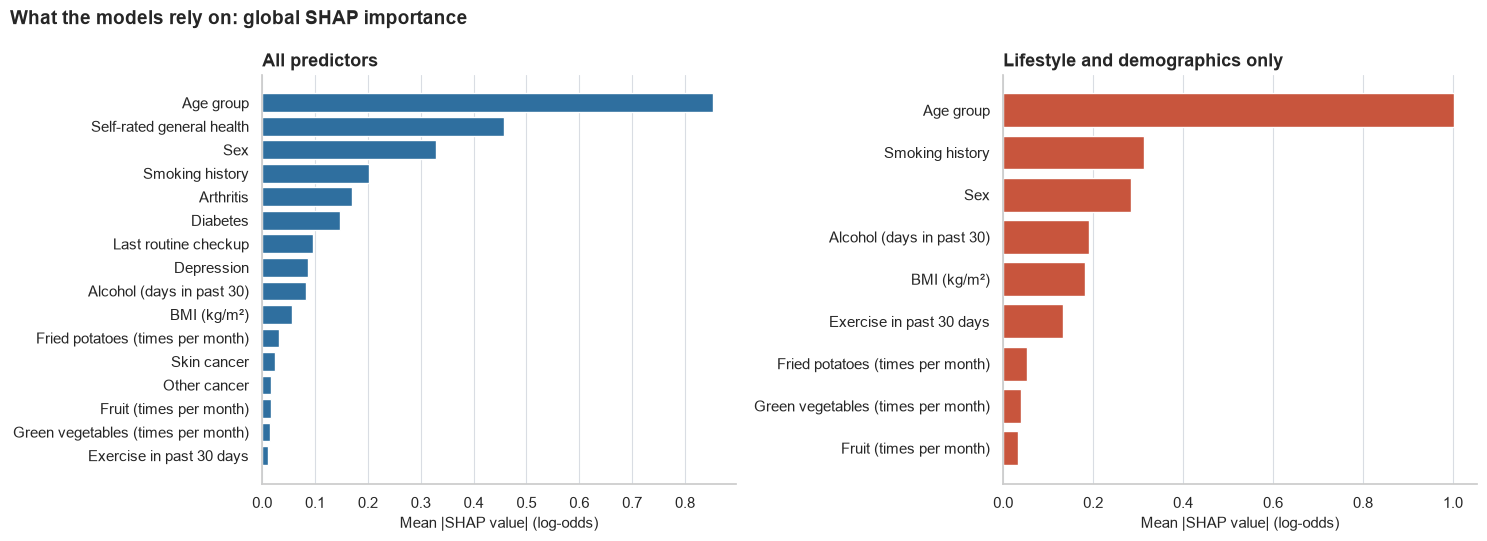

                                      all  lifestyle
Age group                          0.8540     1.0030
Self-rated general health          0.4580        NaN
Sex                                0.3300     0.2840
Smoking history                    0.2020     0.3140
Arthritis                          0.1710        NaN
Diabetes                           0.1470        NaN
Last routine checkup               0.0960        NaN
Depression                         0.0860        NaN
Alcohol (days in past 30)          0.0820     0.1920
BMI (kg/m²)                        0.0570     0.1830
Fried potatoes (times per month)   0.0310     0.0530
Skin cancer                        0.0240        NaN
Other cancer                       0.0170        NaN
Fruit (times per month)            0.0170     0.0330
Green vegetables (times per month) 0.0150     0.0400
Exercise in past 30 days           0.0110     0.1320


In [8]:
shap_sample = test.sample(5000, random_state=SEED)
explanations = {name: models.shap_values(fitted[(name, "LightGBM")], shap_sample) for name in FEATURE_SETS}

importance = {
    name: pd.Series(np.abs(expl.values).mean(axis=0), index=expl.feature_names) for name, expl in explanations.items()
}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plots.horizontal_bar(importance["all"], axes[0], "All predictors", "Mean |SHAP value| (log-odds)")
plots.horizontal_bar(importance["lifestyle"], axes[1], "Lifestyle and demographics only", "Mean |SHAP value| (log-odds)", color=plots.RED)
fig.suptitle("What the models rely on: global SHAP importance", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "shap_importance")
plt.show()

print(pd.DataFrame(importance).sort_values("all", ascending=False).round(3))

**Takeaway.** Age is by far the most important feature in both models, followed in the full model by self-rated general health, sex, smoking history, arthritis and diabetes. The diet variables contribute almost nothing. When the health-status variables are removed, the lifestyle model leans even more heavily on age, and smoking, alcohol, BMI and exercise pick up weight that general health carried. Exercise is the clearest case: its importance rises from 0.01 to 0.13, the same pattern as its odds ratio in notebook 3. This agrees with the logistic regression in notebook 3: the two approaches tell the same story.

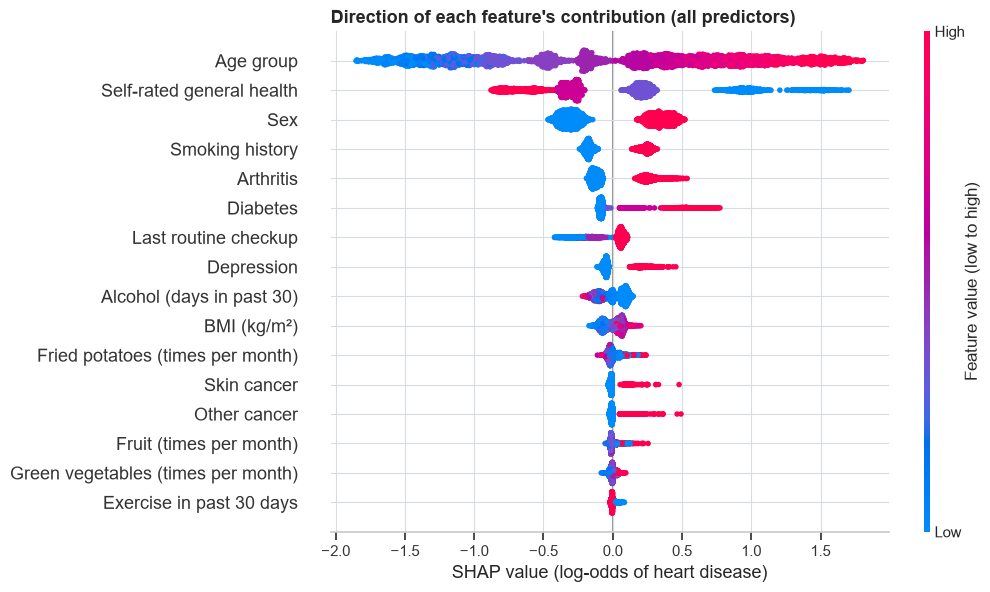

In [9]:
shap.plots.beeswarm(explanations["all"], max_display=16, show=False, color_bar_label="Feature value (low to high)")
fig = plt.gcf()
fig.set_size_inches(9, 6.5)
plt.title("Direction of each feature's contribution (all predictors)", loc="left", fontweight="bold")
plt.xlabel("SHAP value (log-odds of heart disease)")
plt.show()

**How to read this.** Each dot is one respondent; its horizontal position is how much that feature pushed their prediction up (right) or down (left), and its colour is the feature's value. Categorical features are coded in their natural order (age from young to old, general health from Poor to Excellent, No = low and Yes = high).

**Takeaway.** The directions match notebook 3: older age (red) pushes risk up, better self-rated health (red) pushes it down, and being male, diabetic or a smoker pushes it up. Age and general health also have the widest spread, i.e. they can move an individual prediction the most.

### Individual explanations

Three respondents from the test sample: the one with the highest predicted risk, the one closest to the decision threshold, and the one with the lowest predicted risk. In each plot the bars start from the average prediction at the bottom and add up to that person's prediction at the top (both in log-odds).

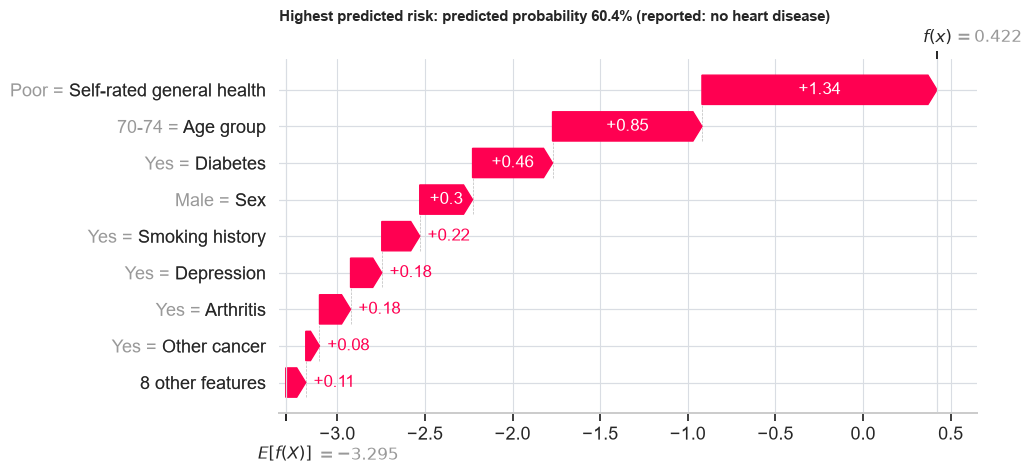

Highest predicted risk: p = 0.604; age_category = 70-74, sex = Male, general_health = Poor, diabetes = Yes, smoking_history = Yes 



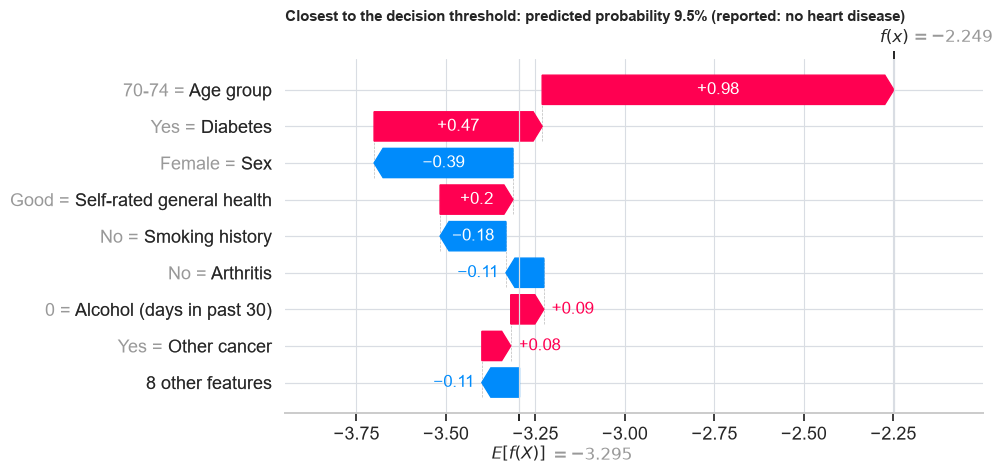

Closest to the decision threshold: p = 0.095; age_category = 70-74, sex = Female, general_health = Good, diabetes = Yes, smoking_history = No 



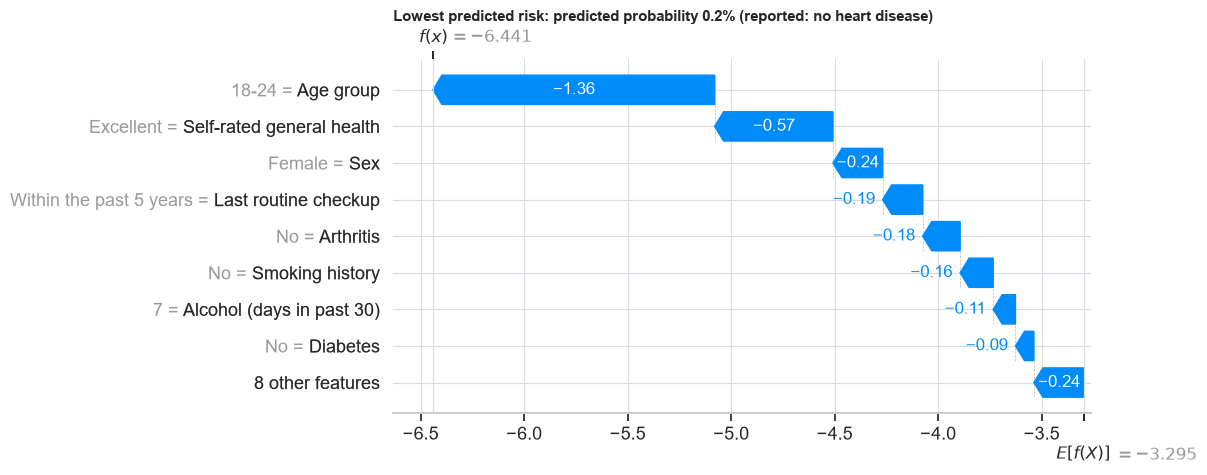

Lowest predicted risk: p = 0.002; age_category = 18-24, sex = Female, general_health = Excellent, diabetes = No, smoking_history = No 



In [10]:
sample_prob = fitted[("all", "LightGBM")].predict_proba(shap_sample[FEATURES_ALL])[:, 1]
picks = {
    "Highest predicted risk": int(np.argmax(sample_prob)),
    "Closest to the decision threshold": int(np.argmin(np.abs(sample_prob - thresholds[("all", "LightGBM")]))),
    "Lowest predicted risk": int(np.argmin(sample_prob)),
}
for label, position in picks.items():
    actual = "heart disease" if shap_sample[TARGET].iloc[position] == 1 else "no heart disease"
    shap.plots.waterfall(explanations["all"][position], max_display=9, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 4.6)
    plt.title(f"{label}: predicted probability {sample_prob[position]:.1%} (reported: {actual})", loc="left", fontweight="bold", fontsize=11)
    plt.show()
    profile = shap_sample[["age_category", "sex", "general_health", "diabetes", "smoking_history"]].iloc[position]
    print(f"{label}: p = {sample_prob[position]:.3f}; " + ", ".join(f"{k} = {v}" for k, v in profile.items()), "\n")

**Takeaway.** The explanations are what a clinician would expect in direction. The highest-risk respondent combines old age with poor self-rated health and further conditions, each adding to the prediction. The lowest-risk respondent is aged 18-24 and in excellent health; age is the largest single reduction, followed by self-rated health. The respondent near the threshold shows how factors offset each other: age 70-74 and diabetes push the prediction up, being female and a non-smoker pull it down.

These explain **the model**, not the person: a SHAP value says how the model used a feature, not that changing the feature would change someone's health.

## 4.6 Saving the models

Both LightGBM pipelines (preprocessing and model together) are saved with the metadata the Streamlit app needs. The `models/` folder is not versioned; running this notebook recreates it.

In [11]:
bundle = {
    "models": {name: fitted[(name, "LightGBM")] for name in FEATURE_SETS},
    "features": dict(FEATURE_SETS),
    "thresholds": {name: thresholds[(name, "LightGBM")] for name in FEATURE_SETS},
    "base_rate": float(base_rate),
    "test_metrics": {name: results.loc[(name, "LightGBM")].to_dict() for name in FEATURE_SETS},
    "numeric_summary": train[data.NUMERIC_COLS].describe().loc[["min", "50%", "max"]].to_dict(),
    "n_train": len(train),
    "seed": SEED,
}
path = models.save_bundle(bundle)
reloaded = models.load_bundle()
check = reloaded["models"]["all"].predict_proba(test[FEATURES_ALL].head(1000))[:, 1]
print(f"Saved {path.relative_to(data.PROJECT_ROOT).as_posix()} ({path.stat().st_size / 1e6:.1f} MB)")
print(f"Reloaded model reproduces the test predictions: {np.allclose(check, test_prob[('all', 'LightGBM')][:1000])}")

Saved models/heart_disease_models.joblib (0.6 MB)
Reloaded model reproduces the test predictions: True


## Summary

- **How well can heart disease be predicted?** Moderately. With all 16 predictors the model reaches a test PR-AUC of 0.317 against a base rate of 0.081, and a ROC-AUC of 0.841. Useful for ranking people by risk, far from sufficient to identify individuals.
- **Lifestyle and demographics alone** give a PR-AUC of 0.241. The difference is the contribution of self-rated health and existing diagnoses, part of which is knowledge a person has only because they are already ill.
- **A simple model is enough.** Logistic regression (PR-AUC 0.315 and 0.237) performs within noise of gradient boosting.
- **Class weights were rejected** in favour of threshold tuning, which preserves calibrated probabilities.
- **The model relies on age first**, then general health, sex and smoking history. Diet variables contribute almost nothing.

**Limitations.** The outcome is self-reported and the data cross-sectional, so the model predicts *who reports* existing heart disease, not who will develop it. The file has no survey weights, so performance on the US population may differ. The model is not a medical tool.